# DATA 245 | Person 4: results analysis (notebook 07)

**What this notebook answers.** What happened in the full experiment, and *why* did the three retraining strategies (static, periodic, drift-triggered) perform so similarly?

**Source of results.** `results/results_v2.csv` is the primary results file (its real-replay rows equal v1; its synthetic rows are the corrected ones from design 1B). `results/results.csv` (v1) is read **only** for the v1-vs-v2 table in section A6. Nothing here changes a setting, model, threshold rule, drift rule or seed, and nothing is tuned.

**Layout.** Part A (core analysis, from `results_v2.csv` only) -> per-row scores (a re-run of the existing loop, needed by Parts B, C and D, and checked to reproduce `results_v2.csv` exactly) -> Part B (diagnostic: oracle ceiling) -> Part C (diagnostic: bootstrap intervals) -> Part D (error analysis).

**Reading guide.**
- *PR-AUC* (precision-recall area under the curve) is the primary metric. A model with no skill scores the window's share of "yes" rows, the *random line*.
- *Lift* = PR-AUC minus that window's random line. It removes the effect of the changing share of "yes".
- *Threshold rule* (for F1, precision, recall only): at every fit (initial and retrain) the cut-off is the best-F1 cut-off on the most recent 1,030 labelled rows, then the model is refitted on all labelled rows. So these three metrics move with the re-tuned cut-off as well as with the model.
- *Synthetic scenarios* (stationary, sudden, gradual) are controlled experiments with separate scoring and history pools, not chronological replays. The real replay is the only real-data evidence.
- All stream settings are **PROPOSED** defaults (see `DECISIONS.md`).

In [1]:
import sys, hashlib, time, warnings
from pathlib import Path
p = Path.cwd().resolve()
root = p if (p / 'src').exists() else p.parent
sys.path.insert(0, str(root))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedKFold

from src.data import encode_target, load_dataset
from src.metrics import evaluate_binary
from src.model_comparison import FEATURE_SETS, positive_scores
from src.scenarios import all_scenarios, real_replay
from src.settings import EXPERIMENT_FEATURE_SET, EXPERIMENT_MODELS, N_STREAM_WINDOWS, PSI_ALERT, SEEDS, STRATEGIES
from src.strategies import make_pipeline, run_all_strategies, summarise

warnings.filterwarnings('ignore')
V1, V2 = root / 'results' / 'results.csv', root / 'results' / 'results_v2.csv'
sha = lambda path: hashlib.sha256(path.read_bytes()).hexdigest()
HASH_AT_START = {V1.name: sha(V1), V2.name: sha(V2)}
FIG, TAB = root / 'figures', root / 'results' / 'tables'
TAB.mkdir(exist_ok=True)

def save_table(frame, name, index=False):
    frame.to_csv(TAB / name, index=index)
    return frame

def save_fig(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches='tight')
    print('saved figures/' + name)

COL = {'static': '#2563EB', 'periodic': '#F97316', 'drift_triggered': '#0D9488'}
LS = {'static': '-', 'periodic': '--', 'drift_triggered': ':'}
MK = {'static': 'o', 'periodic': 's', 'drift_triggered': '^'}
LABEL = {'static': 'Static', 'periodic': 'Periodic (every 2 windows)', 'drift_triggered': 'Drift-triggered'}
SCEN = ['real_replay', 'stationary', 'sudden', 'gradual']
SCEN_TITLE = {'real_replay': 'Real replay (real data)', 'stationary': 'Stationary (synthetic)',
              'sudden': 'Sudden shift (synthetic)', 'gradual': 'Gradual shift (synthetic)'}
MODELS = list(EXPERIMENT_MODELS)
KEYS = ['scenario', 'strategy', 'model', 'seed', 'window']
FEATURES = FEATURE_SETS[EXPERIMENT_FEATURE_SET]
plt.rcParams.update({'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.25, 'axes.spines.top': False, 'axes.spines.right': False})

v2 = pd.read_csv(V2)
v1 = pd.read_csv(V1)
v2['lift'] = v2['pr_auc'] - v2['random_pr_auc']
v1['lift'] = v1['pr_auc'] - v1['random_pr_auc']
print(v2.shape, 'rows in results_v2.csv;', v2.groupby(['scenario', 'strategy', 'model', 'seed']).ngroups, 'runs of 8 windows')
print('Real-replay PR-AUC is identical across the 3 seeds:',
      bool((v2[v2.scenario == 'real_replay'].groupby(['strategy', 'model', 'window'])['pr_auc'].nunique() == 1).all()))

(576, 40) rows in results_v2.csv; 72 runs of 8 windows
Real-replay PR-AUC is identical across the 3 seeds: True


# Part A: core analysis (from `results_v2.csv` only)

## A1. PR-AUC per window

Lines are the three strategies (mean over the 3 seeds); the dashed grey line is that window's random-guess PR-AUC (its share of "yes"). A star marks a window **before which the strategy retrained**. In the real replay the seeds give identical numbers (it does not depend on the seed), so those panels have no spread. In the synthetic panels the shaded band is the range over the 3 seeds.

saved figures/14_real_replay_pr_auc.png


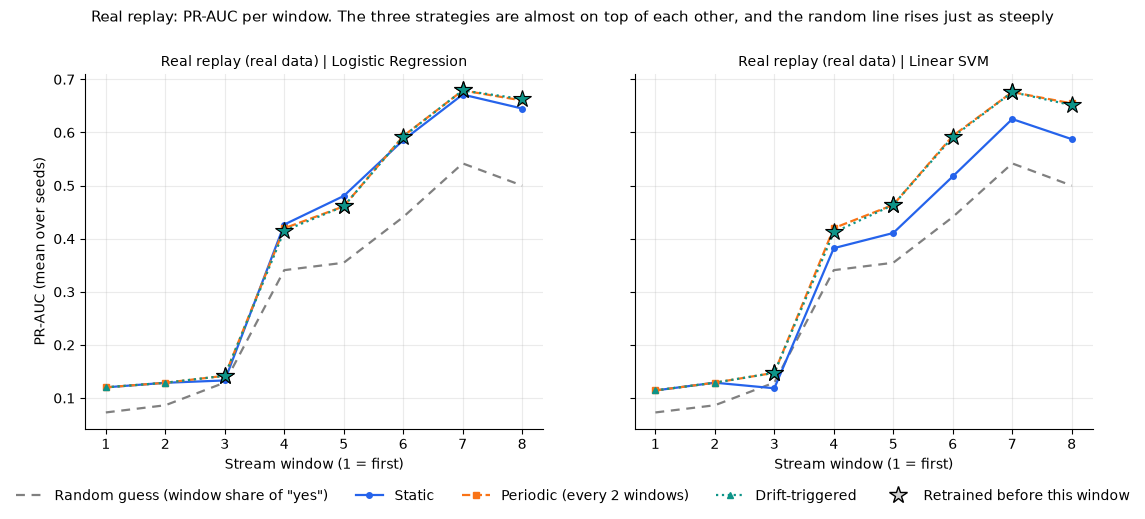

In [2]:
def window_means(frame, value):
    g = frame.groupby(['strategy', 'window'])[value]
    return g.mean().unstack(0), g.min().unstack(0), g.max().unstack(0)

def draw_panel(ax, scenario, model, value, title=None, show_band=True):
    sub = v2[(v2.scenario == scenario) & (v2.model == model)]
    mean, lo, hi = window_means(sub, value)
    random_line = sub.groupby('window')['random_pr_auc'].mean()
    retr = sub.groupby(['strategy', 'window'])['retrained'].max().unstack(0)
    if value == 'pr_auc':
        ax.plot(random_line.index, random_line.values, color='grey', lw=1.6, ls=(0, (4, 3)), label='Random guess (window share of "yes")')
    else:
        ax.axhline(0, color='grey', lw=1.2, ls=(0, (4, 3)), label='Random guess (lift = 0)')
    for s in STRATEGIES:
        if show_band and scenario != 'real_replay':
            ax.fill_between(mean.index, lo[s], hi[s], color=COL[s], alpha=0.12, lw=0)
        ax.plot(mean.index, mean[s], LS[s], color=COL[s], marker=MK[s], ms=4, lw=1.6, label=LABEL[s])
        w = retr.index[retr[s].astype(bool)]
        ax.plot(w, mean.loc[w, s], '*', color=COL[s], mec='black', mew=0.8, ms=13, zorder=5)
    ax.set_xlabel('Stream window (1 = first)')
    ax.set_xticks(range(1, 9))
    ax.set_title(title or f'{SCEN_TITLE[scenario]} | {model}', fontsize=10)

ylab = {'pr_auc': 'PR-AUC (mean over seeds)', 'lift': 'Lift = PR-AUC minus random line'}
# Headline: real replay, both models
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, m in zip(axes, MODELS):
    draw_panel(ax, 'real_replay', m, 'pr_auc')
axes[0].set_ylabel(ylab['pr_auc'])
handles, labels = axes[0].get_legend_handles_labels()
handles.append(plt.Line2D([], [], marker='*', color='w', mfc='lightgrey', mec='black', ms=13)); labels.append('Retrained before this window')
fig.legend(handles, labels, loc='lower center', ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.08))
fig.suptitle('Real replay: PR-AUC per window. The three strategies are almost on top of each other, and the random line rises just as steeply', y=1.02, fontsize=11)
save_fig(fig, '14_real_replay_pr_auc.png'); plt.show()

saved figures/15_all_scenarios_pr_auc.png


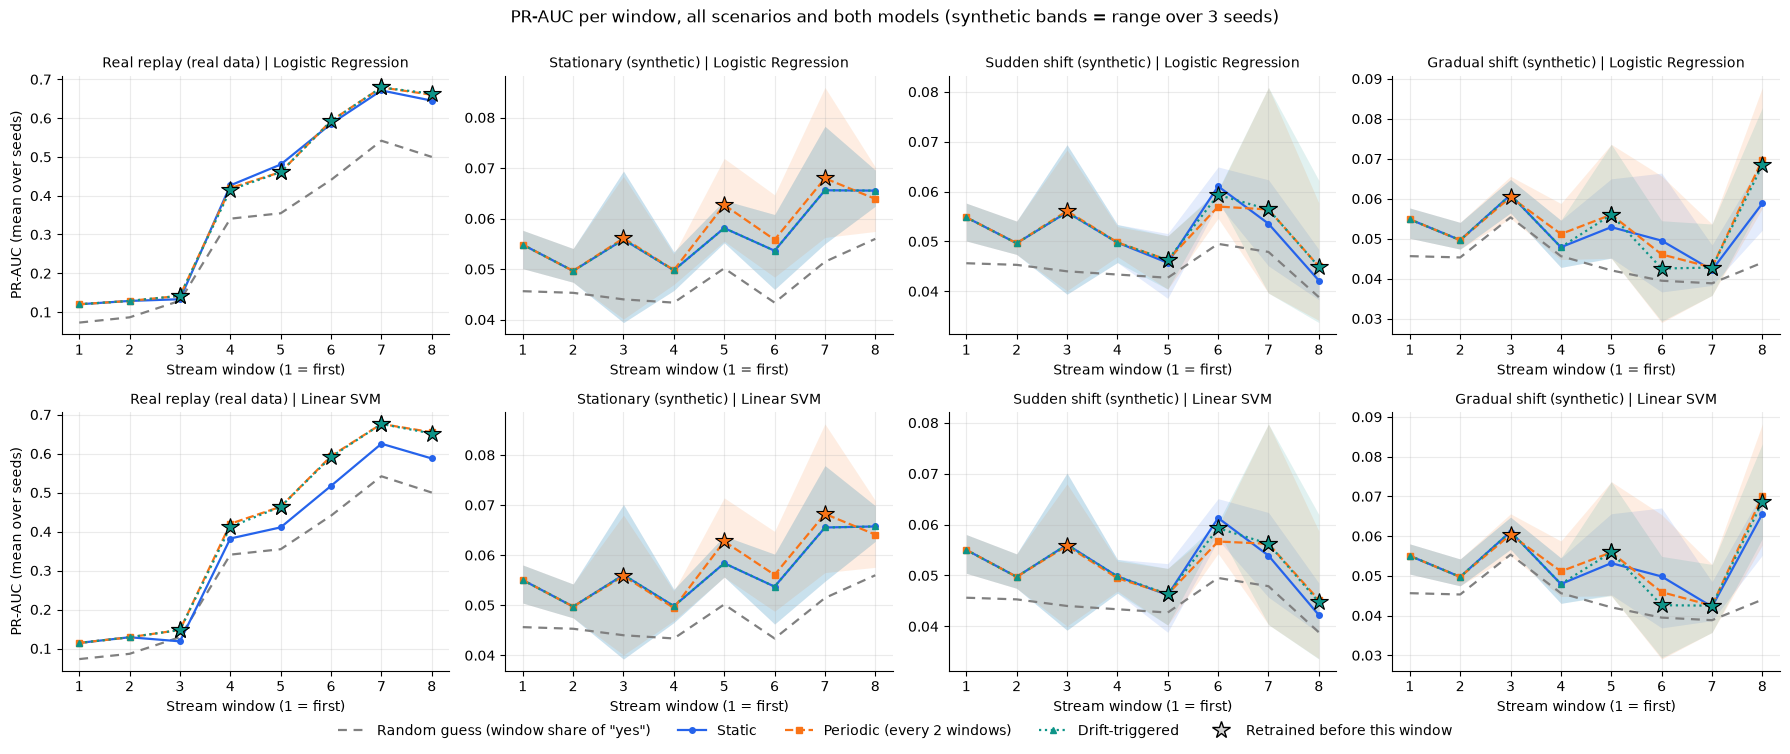

In [3]:
def grid(value, fname, title):
    fig, axes = plt.subplots(2, 4, figsize=(18, 7.2))
    for r, m in enumerate(MODELS):
        for c, s in enumerate(SCEN):
            draw_panel(axes[r, c], s, m, value)
            axes[r, c].set_ylabel(ylab[value] if c == 0 else '')
    handles, labels = axes[0, 0].get_legend_handles_labels()
    handles.append(plt.Line2D([], [], marker='*', color='w', mfc='lightgrey', mec='black', ms=13)); labels.append('Retrained before this window')
    fig.legend(handles, labels, loc='lower center', ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.03))
    fig.suptitle(title, y=1.0, fontsize=12); fig.tight_layout()
    save_fig(fig, fname); plt.show()
grid('pr_auc', '15_all_scenarios_pr_auc.png', 'PR-AUC per window, all scenarios and both models (synthetic bands = range over 3 seeds)')

## A2. The same chart as lift (PR-AUC minus the window's random line)

Lift removes the part of PR-AUC that comes only from the share of "yes" in the window. A lift of 0 means no better than random guessing.

saved figures/16_real_replay_lift.png


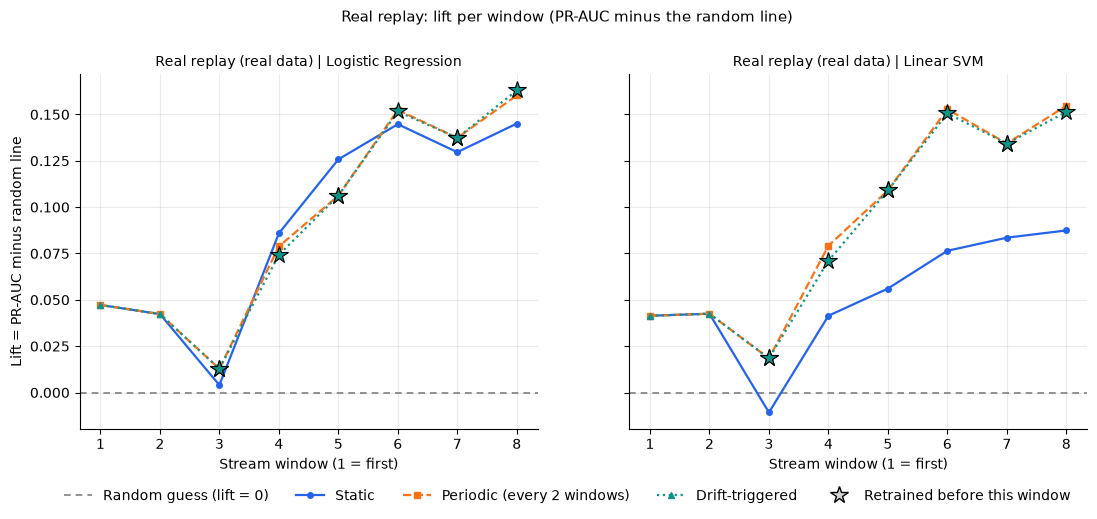

saved figures/17_all_scenarios_lift.png


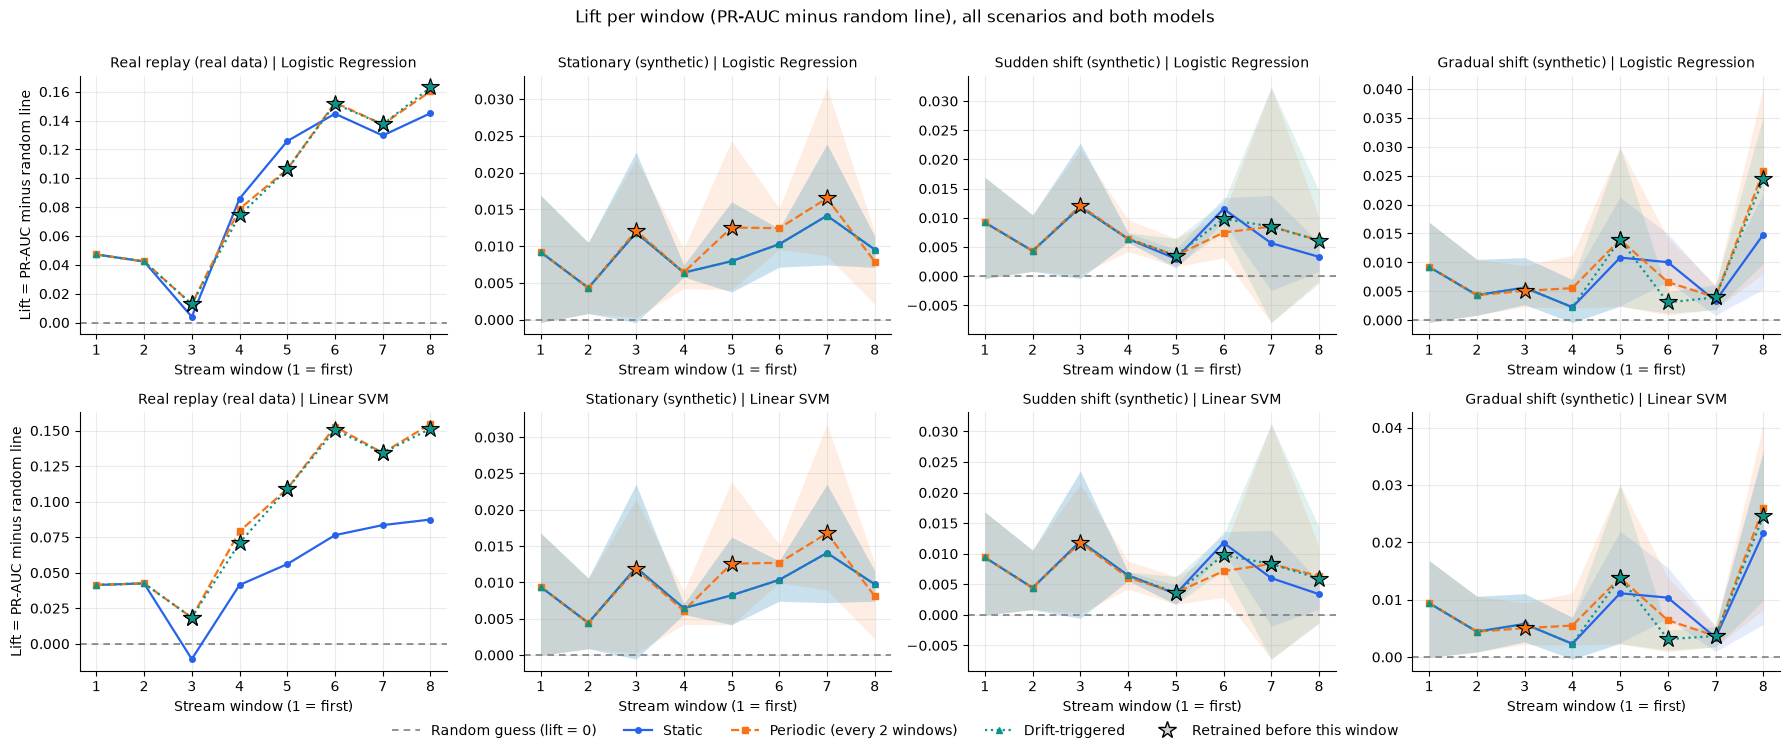

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, m in zip(axes, MODELS):
    draw_panel(ax, 'real_replay', m, 'lift')
axes[0].set_ylabel(ylab['lift'])
handles, labels = axes[0].get_legend_handles_labels()
handles.append(plt.Line2D([], [], marker='*', color='w', mfc='lightgrey', mec='black', ms=13)); labels.append('Retrained before this window')
fig.legend(handles, labels, loc='lower center', ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.08))
fig.suptitle('Real replay: lift per window (PR-AUC minus the random line)', y=1.02, fontsize=11)
save_fig(fig, '16_real_replay_lift.png'); plt.show()
grid('lift', '17_all_scenarios_lift.png', 'Lift per window (PR-AUC minus random line), all scenarios and both models')

## A3. Comparison table per scenario and model

Means over the 8 windows, then over the 3 seeds. F1, precision and recall use each window's recorded cut-off (best F1 on the most recent 1,030 labelled rows, re-tuned at every fit), so they reflect the cut-off rule as well as the model. `retrain_seconds` is the total refitting time in a run; `monitor_seconds` is the drift-monitoring time, which is **logged for every strategy but only the drift-triggered strategy needs it**.

In [5]:
per_run = (v2.groupby(['scenario', 'model', 'strategy', 'seed'])
          .agg(mean_pr_auc=('pr_auc', 'mean'), mean_random_pr_auc=('random_pr_auc', 'mean'), mean_lift=('lift', 'mean'),
               mean_roc_auc=('roc_auc', 'mean'), mean_f1=('f1', 'mean'), mean_precision=('precision', 'mean'), mean_recall=('recall', 'mean'),
               retrains=('retrained', 'sum'), retrain_seconds=('retrain_seconds', 'sum'), monitor_seconds=('monitor_seconds', 'sum'))
          .reset_index())
comparison = (per_run.groupby(['scenario', 'model', 'strategy'])
              .agg(mean_pr_auc=('mean_pr_auc', 'mean'), sd_pr_auc_over_seeds=('mean_pr_auc', 'std'), mean_random_pr_auc=('mean_random_pr_auc', 'mean'),
                   mean_lift=('mean_lift', 'mean'), mean_roc_auc=('mean_roc_auc', 'mean'), mean_f1=('mean_f1', 'mean'), mean_precision=('mean_precision', 'mean'),
                   mean_recall=('mean_recall', 'mean'), retrains=('retrains', 'mean'), retrain_seconds=('retrain_seconds', 'mean'),
                   monitor_seconds=('monitor_seconds', 'mean'))
              .reset_index())
comparison['o'] = comparison.strategy.map({s: i for i, s in enumerate(STRATEGIES)}); comparison['s'] = comparison.scenario.map({s: i for i, s in enumerate(SCEN)})
comparison = comparison.sort_values(['s', 'model', 'o']).drop(columns=['o', 's']).reset_index(drop=True)
save_table(comparison, '07_A3_comparison_table.csv')
comparison.round(4)

,scenario,model,strategy,mean_pr_auc,sd_pr_auc_over_seeds,mean_random_pr_auc,mean_lift,mean_roc_auc,mean_f1,mean_precision,mean_recall,retrains,retrain_seconds,monitor_seconds
0,real_replay,Linear SVM,static,0.3606,0.0000,0.3083,0.0522,0.5328,0.3471,0.3370,0.4074,0.0,0.0000,1.3802
1,real_replay,Linear SVM,periodic,0.3998,0.0000,0.3083,0.0915,0.5811,0.4191,0.3230,0.6502,3.0,0.7186,1.2625
2,real_replay,Linear SVM,drift_triggered,0.3981,0.0000,0.3083,0.0898,0.5792,0.4104,0.3271,0.6264,6.0,1.4774,1.2657
3,real_replay,Logistic Regression,static,0.3989,0.0000,0.3083,0.0906,0.5899,0.4061,0.3594,0.5115,0.0,0.0000,1.3306
4,real_replay,Logistic Regression,periodic,0.4005,0.0000,0.3083,0.0922,0.5826,0.4126,0.3226,0.6386,3.0,1.8169,1.3753
5,real_replay,Logistic Regression,drift_triggered,0.4001,0.0000,0.3083,0.0918,0.5814,0.4084,0.3258,0.6236,6.0,3.4699,1.3916
6,stationary,Linear SVM,static,0.0568,0.0008,0.0474,0.0093,0.5437,0.0835,0.0492,0.2806,0.0,0.0000,0.8913
7,stationary,Linear SVM,periodic,0.0577,0.0012,0.0474,0.0102,0.5448,0.0865,0.0510,0.5031,3.0,0.4384,0.9516
8,stationary,Linear SVM,drift_triggered,0.0568,0.0008,0.0474,0.0093,0.5437,0.0835,0.0492,0.2806,0.0,0.0000,0.8167
9,stationary,Logistic Regression,static,0.0566,0.0008,0.0474,0.0092,0.5425,0.0720,0.0440,0.2011,0.0,0.0000,0.9260


## A4. Drift alerts, detection delay and false alarms, next to the static model's performance (TA question 2)

Alerts are read from the **static** strategy's rows because its drift reference never changes (after a retrain the other strategies' reference changes, so their alert counts are not comparable). The alert depends only on window features, so it is the same for both models; Logistic Regression is shown. Detection delay = first alert at or after the change window minus the change window; false alarms = alerts before the change window (or any alert in the stationary scenario).

In [6]:
st = v2[(v2.strategy == 'static') & (v2.model == 'Logistic Regression')].copy()
rows = []
for (sc, seed), g in st.groupby(['scenario', 'seed']):
    g = g.sort_values('window'); cw = g.change_window.iloc[0]
    if sc == 'real_replay':
        rows.append({'scenario': sc, 'seed': seed, 'change_window': None, 'windows_with_alert': int(g.alert.sum()), 'false_alarms': None, 'first_alert_window': int(g[g.alert].window.min()), 'detection_delay': None})
    elif pd.isna(cw):
        rows.append({'scenario': sc, 'seed': seed, 'change_window': None, 'windows_with_alert': int(g.alert.sum()), 'false_alarms': int(g.alert.sum()), 'first_alert_window': None, 'detection_delay': None})
    else:
        first = g[(g.window >= cw) & g.alert].window.min()
        rows.append({'scenario': sc, 'seed': seed, 'change_window': int(cw), 'windows_with_alert': int(g.alert.sum()), 'false_alarms': int(g[g.window < cw].alert.sum()), 'first_alert_window': int(first), 'detection_delay': int(first - cw)})
detection = pd.DataFrame(rows)
detection['o'] = detection.scenario.map({s: i for i, s in enumerate(SCEN)}); detection = detection.sort_values(['o', 'seed']).drop(columns='o')
save_table(detection, '07_A4_detection_delay_false_alarms.csv')
detection

,scenario,seed,change_window,windows_with_alert,false_alarms,first_alert_window,detection_delay
3,real_replay,42,NaN,8,NaN,1.0,NaN
4,real_replay,43,NaN,8,NaN,1.0,NaN
5,real_replay,44,NaN,8,NaN,1.0,NaN
6,stationary,42,NaN,0,0.0,NaN,NaN
7,stationary,43,NaN,0,0.0,NaN,NaN
8,stationary,44,NaN,0,0.0,NaN,NaN
9,sudden,42,5.0,4,0.0,5.0,0.0
10,sudden,43,5.0,4,0.0,5.0,0.0
11,sudden,44,5.0,4,0.0,5.0,0.0
0,gradual,42,3.0,4,0.0,5.0,2.0


In [7]:
# Do alerts line up with real performance drops? Static model before vs. after the change window (synthetic), per seed.
rows = []
for (sc, seed), g in st[st.scenario.isin(['sudden', 'gradual'])].groupby(['scenario', 'seed']):
    cw = int(g.change_window.iloc[0]); pre, post = g[g.window < cw], g[g.window >= cw]
    rows.append({'scenario': sc, 'seed': seed, 'change_window': cw,
                 'static_pr_auc_before': pre.pr_auc.mean(), 'static_pr_auc_after': post.pr_auc.mean(),
                 'static_lift_before': pre.lift.mean(), 'static_lift_after': post.lift.mean(),
                 'yes_share_before': pre.random_pr_auc.mean(), 'yes_share_after': post.random_pr_auc.mean(),
                 'alert_windows_before': int(pre.alert.sum()), 'alert_windows_after': int(post.alert.sum())})
before_after = pd.DataFrame(rows)
save_table(before_after, '07_A4_static_before_vs_after_change.csv')
display(before_after.round(4))
print('Mean over seeds of (after - before) static lift:', before_after.assign(d=before_after.static_lift_after - before_after.static_lift_before).groupby('scenario').d.mean().round(4).to_dict())

# Real replay: the alert fires every window, so there is nothing to compare windows with; correlation of alert size with performance (8 points, descriptive)
rr = st[(st.scenario == 'real_replay') & (st.seed == 42)].sort_values('window')
rho_lift = spearmanr(rr.max_psi_trigger_groups, rr.lift); rho_pr = spearmanr(rr.max_psi_trigger_groups, rr.pr_auc)
print(f'Real replay: alert fires in {int(rr.alert.sum())} of 8 windows. Spearman(max PSI, static PR-AUC) = {rho_pr.statistic:.2f}; Spearman(max PSI, static lift) = {rho_lift.statistic:.2f} (8 points, descriptive only)')

,scenario,seed,change_window,static_pr_auc_before,static_pr_auc_after,static_lift_before,static_lift_after,yes_share_before,yes_share_after,alert_windows_before,alert_windows_after
0,gradual,42,3,0.0525,0.0527,0.0108,0.0077,0.0417,0.0450,0,4
1,gradual,43,3,0.0521,0.0516,0.0006,0.0071,0.0515,0.0445,0,4
2,gradual,44,3,0.0521,0.0518,0.0089,0.0086,0.0432,0.0432,0,4
3,sudden,42,5,0.0551,0.0490,0.0126,0.0056,0.0425,0.0434,0,4
4,sudden,43,5,0.0492,0.0504,0.0017,0.0084,0.0476,0.0420,0,4
5,sudden,44,5,0.0533,0.0525,0.0096,0.0037,0.0437,0.0488,0,4


Mean over seeds of (after - before) static lift: {'gradual': 0.001, 'sudden': -0.0021}
Real replay: alert fires in 8 of 8 windows. Spearman(max PSI, static PR-AUC) = 0.76; Spearman(max PSI, static lift) = 0.90 (8 points, descriptive only)


In [8]:
# Did retraining help after an alert? Difference in PR-AUC from the static model, in the same window and seed,
# only for windows scored by a retrained model (model_version > 0).
wide = v2.pivot_table(index=['scenario', 'model', 'seed', 'window'], columns='strategy', values=['pr_auc', 'model_version']).reset_index()
wide.columns = ['_'.join(c).strip('_') for c in wide.columns]
rows = []
for strat in ['periodic', 'drift_triggered']:
    sub = wide[wide[f'model_version_{strat}'] > 0].copy()
    sub['delta'] = sub[f'pr_auc_{strat}'] - sub['pr_auc_static']
    per = sub.groupby(['scenario', 'model', 'seed']).agg(windows=('delta', 'size'), mean_delta=('delta', 'mean'), windows_better=('delta', lambda d: int((d > 0).sum()))).reset_index()
    out = per.groupby(['scenario', 'model']).agg(windows_after_first_retrain_per_run=('windows', 'mean'), mean_pr_auc_gain_over_static=('mean_delta', 'mean'),
                                                 windows_better_than_static_per_run=('windows_better', 'mean')).reset_index()
    out.insert(2, 'strategy', strat)
    rows.append(out)
retrain_effect = pd.concat(rows, ignore_index=True)
retrain_effect['s'] = retrain_effect.scenario.map({s: i for i, s in enumerate(SCEN)})
retrain_effect = retrain_effect.sort_values(['s', 'model', 'strategy']).drop(columns='s').reset_index(drop=True)
save_table(retrain_effect, '07_A4_retraining_effect_vs_static.csv')
retrain_effect.round(4)

,scenario,model,strategy,windows_after_first_retrain_per_run,mean_pr_auc_gain_over_static,windows_better_than_static_per_run
0,real_replay,Linear SVM,drift_triggered,6.0,0.0501,6.0000
1,real_replay,Linear SVM,periodic,6.0,0.0524,6.0000
2,real_replay,Logistic Regression,drift_triggered,6.0,0.0017,4.0000
3,real_replay,Logistic Regression,periodic,6.0,0.0021,4.0000
4,stationary,Linear SVM,periodic,6.0,0.0012,3.3333
5,stationary,Logistic Regression,periodic,6.0,0.0013,4.0000
6,sudden,Linear SVM,drift_triggered,4.0,0.0008,1.6667
7,sudden,Linear SVM,periodic,6.0,0.0000,2.6667
8,sudden,Logistic Regression,drift_triggered,4.0,0.0011,1.6667
9,sudden,Logistic Regression,periodic,6.0,0.0004,2.6667


saved figures/18_alerts_vs_static_performance.png


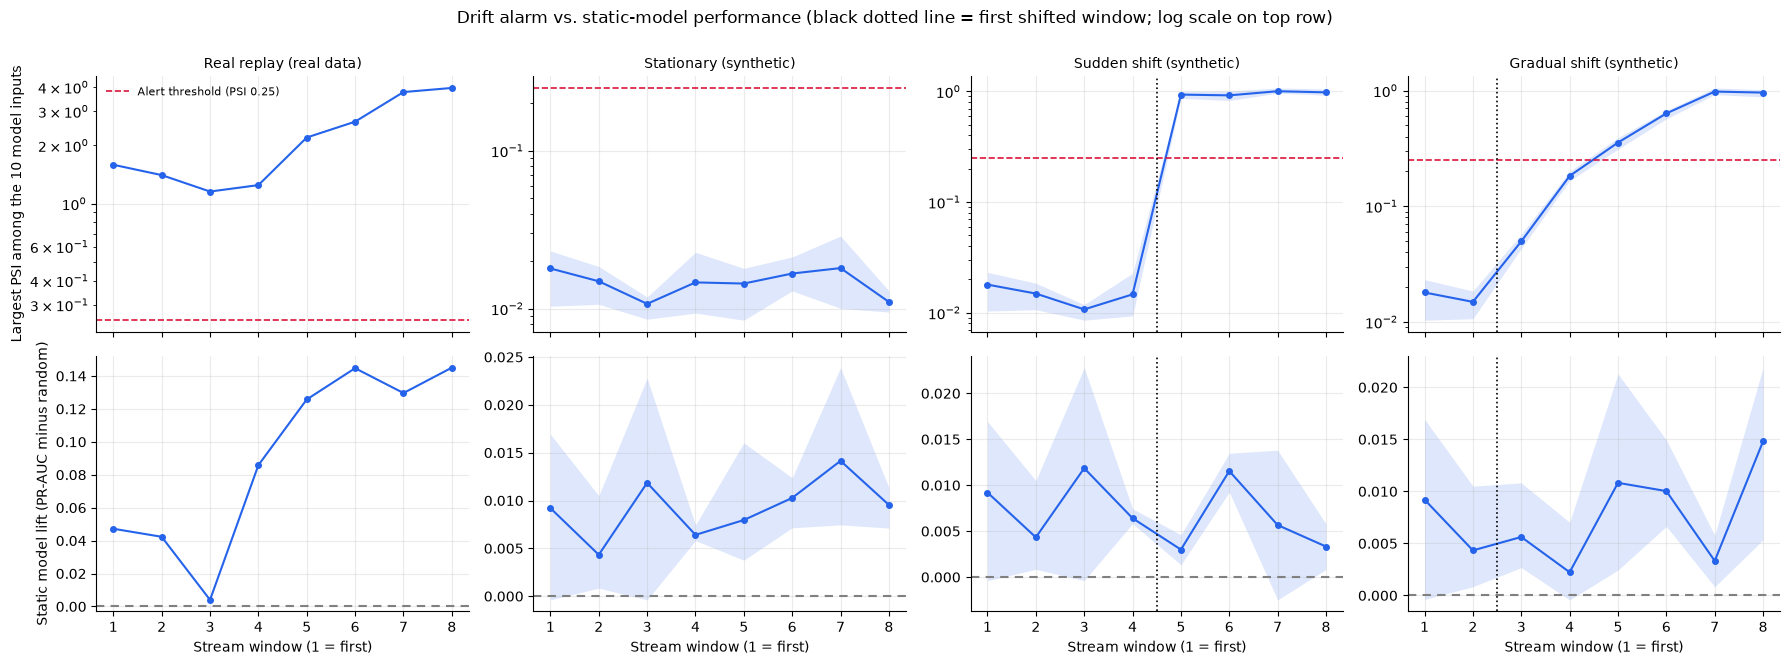

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(18, 6.6), sharex=True)
for c, s in enumerate(SCEN):
    sub = st[st.scenario == s]
    g = sub.groupby('window')
    for ax, col, ylabel in ((axes[0, c], 'max_psi_trigger_groups', 'Largest PSI among the 10 model inputs'), (axes[1, c], 'lift', 'Static model lift (PR-AUC minus random)')):
        m = g[col].mean(); ax.plot(m.index, m.values, '-o', color=COL['static'], ms=4)
        if s != 'real_replay': ax.fill_between(m.index, g[col].min(), g[col].max(), color=COL['static'], alpha=0.15, lw=0)
        ax.set_xticks(range(1, 9)); ax.set_ylabel(ylabel if c == 0 else '')
    axes[0, c].axhline(PSI_ALERT, color='crimson', ls='--', lw=1.2, label='Alert threshold (PSI 0.25)')
    axes[0, c].set_yscale('log'); axes[0, c].set_title(SCEN_TITLE[s], fontsize=10)
    axes[1, c].axhline(0, color='grey', ls=(0, (4, 3))); axes[1, c].set_xlabel('Stream window (1 = first)')
    cw = sub.change_window.dropna()
    if len(cw):
        for ax in axes[:, c]: ax.axvline(cw.iloc[0] - 0.5, color='black', ls=':', lw=1.2)
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle('Drift alarm vs. static-model performance (black dotted line = first shifted window; log scale on top row)', y=1.0, fontsize=12)
fig.tight_layout(); save_fig(fig, '18_alerts_vs_static_performance.png'); plt.show()

## A5. Real replay: why raw PR-AUC rises

The share of "yes" in the real stream rises from about 7% to over 50%. PR-AUC of random guessing equals that share, so raw PR-AUC rises with it even if the model's ranking quality does not change.

,window,yes_share_(random_PR_AUC),static_LR_PR_AUC,lift,PR_AUC_over_random_ratio,static_LR_ROC_AUC
0,1,0.073,0.120,0.047,1.648,0.599
1,2,0.086,0.129,0.042,1.490,0.511
2,3,0.129,0.133,0.004,1.031,0.479
3,4,0.341,0.427,0.086,1.252,0.585
4,5,0.355,0.480,0.126,1.354,0.603
5,6,0.441,0.586,0.145,1.328,0.629
6,7,0.542,0.671,0.130,1.239,0.639
7,8,0.500,0.645,0.145,1.290,0.674


Window 1 -> 7: PR-AUC rose by 0.551; the random line rose by 0.469 (85% of the PR-AUC rise); lift rose by 0.082.
Pearson correlation of yes share with PR-AUC: 0.995 | with lift: 0.908 (8 windows, descriptive)


saved figures/19_real_replay_yes_share_vs_pr_auc.png


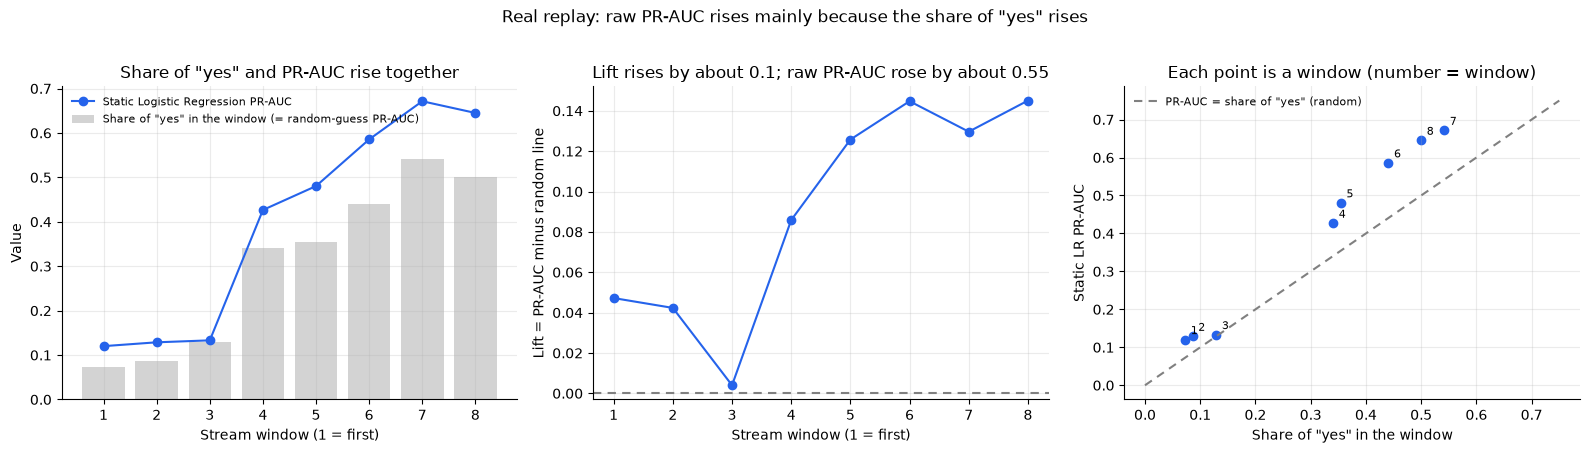

In [10]:
rr = v2[(v2.scenario == 'real_replay') & (v2.strategy == 'static') & (v2.model == 'Logistic Regression') & (v2.seed == 42)].sort_values('window')
share = pd.DataFrame({'window': rr.window.values, 'yes_share_(random_PR_AUC)': rr.random_pr_auc.values, 'static_LR_PR_AUC': rr.pr_auc.values,
                      'lift': rr.lift.values, 'PR_AUC_over_random_ratio': (rr.pr_auc / rr.random_pr_auc).values, 'static_LR_ROC_AUC': rr.roc_auc.values})
save_table(share, '07_A5_yes_share_vs_pr_auc.csv')
display(share.round(3))
w1, w7 = share.iloc[0], share.iloc[6]
rise_pr = w7['static_LR_PR_AUC'] - w1['static_LR_PR_AUC']; rise_rand = w7['yes_share_(random_PR_AUC)'] - w1['yes_share_(random_PR_AUC)']
print(f'Window 1 -> 7: PR-AUC rose by {rise_pr:.3f}; the random line rose by {rise_rand:.3f} ({100 * rise_rand / rise_pr:.0f}% of the PR-AUC rise); lift rose by {w7.lift - w1.lift:.3f}.')
print('Pearson correlation of yes share with PR-AUC:', round(pearsonr(share.iloc[:, 1], share.static_LR_PR_AUC)[0], 3), '| with lift:', round(pearsonr(share.iloc[:, 1], share.lift)[0], 3), '(8 windows, descriptive)')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
ax = axes[0]; ax.bar(share.window, share.iloc[:, 1], color='lightgrey', label='Share of "yes" in the window (= random-guess PR-AUC)')
ax.plot(share.window, share.static_LR_PR_AUC, '-o', color=COL['static'], label='Static Logistic Regression PR-AUC'); ax.set_xlabel('Stream window (1 = first)'); ax.set_ylabel('Value'); ax.legend(frameon=False, fontsize=8, loc='upper left'); ax.set_title('Share of "yes" and PR-AUC rise together')
ax = axes[1]; ax.plot(share.window, share.lift, '-o', color=COL['static']); ax.axhline(0, color='grey', ls=(0, (4, 3))); ax.set_xlabel('Stream window (1 = first)'); ax.set_ylabel('Lift = PR-AUC minus random line'); ax.set_title('Lift rises by about 0.1; raw PR-AUC rose by about 0.55')
ax = axes[2]; ax.scatter(share.iloc[:, 1], share.static_LR_PR_AUC, color=COL['static']); [ax.annotate(str(int(w)), (x, y), textcoords='offset points', xytext=(4, 4), fontsize=8) for w, x, y in zip(share.window, share.iloc[:, 1], share.static_LR_PR_AUC)]
lim = [0, 0.75]; ax.plot(lim, lim, color='grey', ls=(0, (4, 3)), label='PR-AUC = share of "yes" (random)'); ax.set_xlabel('Share of "yes" in the window'); ax.set_ylabel('Static LR PR-AUC'); ax.legend(frameon=False, fontsize=8); ax.set_title('Each point is a window (number = window)')
fig.suptitle('Real replay: raw PR-AUC rises mainly because the share of "yes" rises', y=1.02, fontsize=12); fig.tight_layout()
save_fig(fig, '19_real_replay_yes_share_vs_pr_auc.png'); plt.show()

## A6. v1 versus v2 (synthetic scenarios)

v1 (`results.csv`) is known to contain row reuse; v2 fixes it. **v1 and v2 differ in more than one factor**: v2 also fits the initial model on 60% instead of 80% of the training rows and uses different random draws. So the table shows that the apparent retraining gain shrinks, which is consistent with the row reuse having inflated v1, but it does not isolate the row reuse as the only cause. The real-replay rows are identical (checked in notebook 06b).

In [11]:
s1, s2 = summarise(v1), summarise(v2)
cmp = s1.merge(s2, on=['scenario', 'strategy', 'model'], suffixes=('_v1', '_v2')).query("scenario != 'real_replay'")
w = cmp.pivot_table(index=['scenario', 'model'], columns='strategy', values=['mean_pr_auc_v1', 'mean_pr_auc_v2'])
v1v2 = pd.DataFrame({
    'static_v1': w['mean_pr_auc_v1']['static'], 'static_v2': w['mean_pr_auc_v2']['static'],
    'periodic_gain_v1': w['mean_pr_auc_v1']['periodic'] - w['mean_pr_auc_v1']['static'], 'periodic_gain_v2': w['mean_pr_auc_v2']['periodic'] - w['mean_pr_auc_v2']['static'],
    'drift_gain_v1': w['mean_pr_auc_v1']['drift_triggered'] - w['mean_pr_auc_v1']['static'], 'drift_gain_v2': w['mean_pr_auc_v2']['drift_triggered'] - w['mean_pr_auc_v2']['static'],
    'random_line_v1': cmp[cmp.strategy == 'static'].set_index(['scenario', 'model']).mean_random_pr_auc_v1,
    'random_line_v2': cmp[cmp.strategy == 'static'].set_index(['scenario', 'model']).mean_random_pr_auc_v2}).reset_index()
v1v2['s'] = v1v2.scenario.map({s: i for i, s in enumerate(SCEN)}); v1v2 = v1v2.sort_values(['s', 'model']).drop(columns='s')
save_table(v1v2, '07_A6_v1_vs_v2_synthetic.csv')
v1v2.round(4)

,scenario,model,static_v1,static_v2,periodic_gain_v1,periodic_gain_v2,drift_gain_v1,drift_gain_v2,random_line_v1,random_line_v2
2,stationary,Linear SVM,0.0498,0.0568,0.0021,0.0009,0.0000,0.0000,0.0417,0.0474
3,stationary,Logistic Regression,0.0500,0.0566,0.0020,0.0010,0.0000,0.0000,0.0417,0.0474
4,sudden,Linear SVM,0.0619,0.0518,0.0055,0.0000,0.0063,0.0004,0.0445,0.0447
5,sudden,Logistic Regression,0.0625,0.0516,0.0054,0.0003,0.0062,0.0006,0.0445,0.0447
0,gradual,Linear SVM,0.0649,0.0531,0.0043,0.0007,0.0045,-0.0002,0.0431,0.0445
1,gradual,Logistic Regression,0.0650,0.0521,0.0040,0.0017,0.0042,0.0008,0.0431,0.0445


## A7. How much of a retrained model's training data is recent? (real replay)

A retrain refits on **all** labelled rows so far (expanding history). If most of those rows are old, a retrain can only change the model a little. The table shows, for Logistic Regression and seed 42, how many of the rows the scoring model was trained on came from the stream, against the 24,712 original training rows (positive rate shown for comparison).

Original training rows: 24,712 with 4.8% "yes". The stream windows hold 7% to 54% "yes" (section A5).


,strategy,window,retrained,n_train_rows,labelled_windows_in_model,stream_rows_in_training,share_of_training_rows_from_stream,threshold,alert
8,periodic,1,False,24712,0,0,0.000,0.523,True
9,periodic,2,False,24712,0,0,0.000,0.523,True
10,periodic,3,True,25741,1,1029,0.040,0.543,True
11,periodic,4,False,25741,1,1029,0.040,0.543,True
12,periodic,5,True,27801,3,3089,0.111,0.425,True
13,periodic,6,False,27801,3,3089,0.111,0.425,True
14,periodic,7,True,29860,5,5148,0.172,0.448,True
15,periodic,8,False,29860,5,5148,0.172,0.448,True
16,drift_triggered,1,False,24712,0,0,0.000,0.523,True
17,drift_triggered,2,False,24712,0,0,0.000,0.523,True


saved figures/23_real_replay_training_set_composition.png


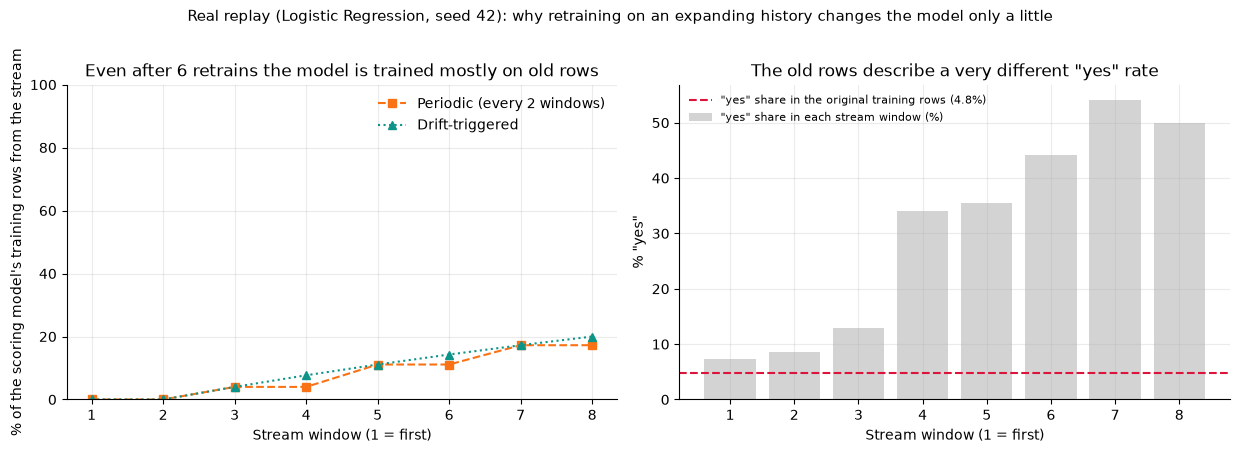

In [12]:
df = load_dataset()
initial_rows = real_replay(df).initial_train
old_yes_rate = float(encode_target(initial_rows).mean())
rr_ = v2[(v2.scenario == 'real_replay') & (v2.model == 'Logistic Regression') & (v2.seed == 42) & (v2.strategy.isin(['periodic', 'drift_triggered']))].copy()
rr_['stream_rows_in_training'] = rr_.n_train_rows - len(initial_rows)
rr_['share_of_training_rows_from_stream'] = rr_.stream_rows_in_training / rr_.n_train_rows
composition = rr_[['strategy', 'window', 'retrained', 'n_train_rows', 'labelled_windows_in_model', 'stream_rows_in_training', 'share_of_training_rows_from_stream', 'threshold', 'alert']]
save_table(composition, '07_A7_training_set_composition.csv')
print(f'Original training rows: {len(initial_rows):,} with {100 * old_yes_rate:.1f}% "yes". The stream windows hold 7% to 54% "yes" (section A5).')
display(composition.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
ax = axes[0]
for s_ in ['periodic', 'drift_triggered']:
    c_ = composition[composition.strategy == s_]
    ax.plot(c_.window, 100 * c_.share_of_training_rows_from_stream, LS[s_], color=COL[s_], marker=MK[s_], label=LABEL[s_])
ax.set_xlabel('Stream window (1 = first)'); ax.set_ylabel("% of the scoring model's training rows from the stream"); ax.set_ylim(0, 100)
ax.set_xticks(range(1, 9)); ax.legend(frameon=False); ax.set_title('Even after 6 retrains the model is trained mostly on old rows')
ax = axes[1]
ys = rr[['window', 'random_pr_auc']]
ax.bar(ys.window, 100 * ys.random_pr_auc, color='lightgrey', label='"yes" share in each stream window (%)')
ax.axhline(100 * old_yes_rate, color='crimson', ls='--', label=f'"yes" share in the original training rows ({100 * old_yes_rate:.1f}%)')
ax.set_xlabel('Stream window (1 = first)'); ax.set_ylabel('% "yes"'); ax.set_xticks(range(1, 9)); ax.legend(frameon=False, fontsize=8); ax.set_title('The old rows describe a very different "yes" rate')
fig.suptitle('Real replay (Logistic Regression, seed 42): why retraining on an expanding history changes the model only a little', y=1.02, fontsize=11)
fig.tight_layout(); save_fig(fig, '23_real_replay_training_set_composition.png'); plt.show()

# Per-row scores (needed by Parts B, C and D)

`results_v2.csv` holds only per-window aggregates. To get per-row scores I **re-run the existing strategy loop** (same scenarios, models, seeds and settings) with the optional `scores_out` argument of `run_strategy`, which only records scores and changes nothing else. Before any score is used, **every metric recomputed from the scores must equal `results_v2.csv` exactly**; the cell stops with an error otherwise.

In [13]:
df = load_dataset()
t0 = time.perf_counter(); store, reruns = [], []
for seed in SEEDS:
    for sc in all_scenarios(df, seed=seed):
        for model_name in MODELS:
            out = []
            res = run_all_strategies(sc, model_name, seed, scores_out=out)
            for e in out: e.update(scenario=sc.name, model=model_name, seed=seed)
            store.extend(out); reruns.append(res)
rerun = pd.concat(reruns, ignore_index=True)
print(f'Re-run finished in {time.perf_counter() - t0:.0f} s: {len(store)} windows with per-row scores')

Re-run finished in 125 s: 576 windows with per-row scores


In [14]:
v2i = v2.set_index(KEYS)
METRIC_COLS = ['n_rows', 'n_positive', 'pr_auc', 'random_pr_auc', 'roc_auc', 'f1', 'precision', 'recall', 'tp', 'fp', 'fn', 'tn', 'n_predicted_positive', 'threshold']
mismatches = []
for e in store:
    m = evaluate_binary(e['y'], e['scores'], threshold=e['threshold'])
    row = v2i.loc[(e['scenario'], e['strategy'], e['model'], e['seed'], e['window'])]
    for c in METRIC_COLS:
        if m[c] != row[c]:
            mismatches.append((e['scenario'], e['strategy'], e['model'], e['seed'], e['window'], c, m[c], row[c]))
print(f'Metrics recomputed from per-row scores: {len(store) * len(METRIC_COLS)} values compared, {len(mismatches)} differ')
assert not mismatches, mismatches[:5]

# The re-run's non-timing columns must also equal results_v2.csv (same decisions, same models)
TIMING = ['retrain_seconds', 'monitor_seconds', 'initial_fit_seconds']
import io
rerun_csv = pd.read_csv(io.StringIO(rerun.to_csv(index=False)))      # same CSV round trip as results_v2.csv, so formats match
a = rerun_csv.set_index(KEYS).sort_index(); b = v2.drop(columns='lift').set_index(KEYS).sort_index()
assert list(a.index) == list(b.index), 'row keys differ'
differ = []
for c in [c for c in b.columns if c not in TIMING]:
    x, y = a[c], b[c]
    if pd.api.types.is_numeric_dtype(x) and not pd.api.types.is_bool_dtype(x):
        bad = int((~((x == y) | (x.isna() & y.isna()))).sum())
    else:
        bad = int((x.fillna('').astype(str) != y.fillna('').astype(str)).sum())
    if bad: differ.append((c, bad))
print('Non-timing columns of the re-run that differ from results_v2.csv:', differ or 'none (all identical)')
assert not differ, differ
print('Per-row scores reproduce results_v2.csv exactly; safe to use.')
idx_store = {(e['scenario'], e['model'], e['seed'], e['strategy'], e['window']): e for e in store}

Metrics recomputed from per-row scores: 8064 values compared, 0 differ
Non-timing columns of the re-run that differ from results_v2.csv: none (all identical)
Per-row scores reproduce results_v2.csv exactly; safe to use.


# Part B: DIAGNOSTIC 1, an "oracle ceiling" (real replay only)

> **DIAGNOSTIC ONLY. This uses the labels of the very window being scored, which a real deployment would not have yet. It must never be used to choose any setting, model or rule.**

**Question.** If even a model trained on a window's *own* labels cannot do much better than the static model, then no retraining strategy could have helped much.

**Method.** For each real-replay window: stratified 5-fold cross-validation (shuffled, fixed seed 42) inside the window, with the same two model types, the same configurations, the same 10 features and the same preprocessing as the experiment (`make_pipeline`; the preprocessing is fitted inside each fold's training part). For a like-for-like comparison, the three strategies' per-row scores are evaluated on **the same held-out fold rows**.

**Limits.** A window has only about 1,000 rows (about 820 for training in each fold), so this is a *small-sample* ceiling, not a true upper bound: a model with more recent data might do better. Early windows have few "yes" rows (75 to 133), so their folds hold only 15 to 27 "yes" and the ceiling there is noisy. Synthetic scenarios are skipped: their windows draw the same row several times, which would leak duplicates across folds and inflate the ceiling.

In [15]:
rows = []
for model_name in MODELS:
    for w, win in enumerate(real_replay(df).windows, start=1):
        X, y = win[FEATURES], encode_target(win).to_numpy()
        skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        for k, (tr, te) in enumerate(skf.split(X, y)):
            pipe = make_pipeline(model_name, seed=42).fit(X.iloc[tr], y[tr])
            row = {'model': model_name, 'window': w, 'fold': k, 'n_test': len(te), 'n_positive_test': int(y[te].sum()),
                   'random_pr_auc': y[te].mean(), 'oracle_pr_auc': average_precision_score(y[te], positive_scores(pipe, X.iloc[te]))}
            for s in STRATEGIES:
                e = idx_store[('real_replay', model_name, 42, s, w)]
                assert np.array_equal(e['index'], win.index.to_numpy()) and np.array_equal(e['y'], y)
                row[s] = average_precision_score(y[te], e['scores'][te])
            rows.append(row)
folds = pd.DataFrame(rows)
ceiling = (folds.groupby(['model', 'window'])
           .agg(oracle_mean=('oracle_pr_auc', 'mean'), oracle_sd_over_folds=('oracle_pr_auc', 'std'), random_line=('random_pr_auc', 'mean'),
                static=('static', 'mean'), periodic=('periodic', 'mean'), drift_triggered=('drift_triggered', 'mean')).reset_index())
ceiling['oracle_minus_static'] = ceiling.oracle_mean - ceiling.static
ceiling['oracle_lift'] = ceiling.oracle_mean - ceiling.random_line
ceiling['static_lift'] = ceiling.static - ceiling.random_line
save_table(ceiling, '07_B_oracle_ceiling.csv')
display(ceiling.round(3))
summ = ceiling.groupby('model').agg(mean_oracle=('oracle_mean', 'mean'), mean_static=('static', 'mean'), mean_periodic=('periodic', 'mean'), mean_drift=('drift_triggered', 'mean'),
                                    mean_random=('random_line', 'mean'), mean_oracle_lift=('oracle_lift', 'mean'), mean_static_lift=('static_lift', 'mean')).reset_index()
save_table(summ, '07_B_oracle_ceiling_summary.csv'); display(summ.round(3))

,model,window,oracle_mean,oracle_sd_over_folds,random_line,static,periodic,drift_triggered,oracle_minus_static,oracle_lift,static_lift
0,Linear SVM,1,0.104,0.040,0.073,0.160,0.160,0.160,-0.056,0.031,0.087
1,Linear SVM,2,0.128,0.025,0.086,0.161,0.161,0.161,-0.033,0.041,0.075
2,Linear SVM,3,0.170,0.038,0.129,0.137,0.169,0.169,0.033,0.041,0.008
3,Linear SVM,4,0.385,0.033,0.341,0.389,0.436,0.434,-0.004,0.044,0.048
4,Linear SVM,5,0.482,0.059,0.355,0.415,0.472,0.472,0.066,0.127,0.060
5,Linear SVM,6,0.586,0.023,0.441,0.524,0.599,0.597,0.062,0.145,0.084
6,Linear SVM,7,0.686,0.021,0.542,0.634,0.682,0.682,0.053,0.145,0.092
7,Linear SVM,8,0.696,0.053,0.500,0.595,0.660,0.657,0.101,0.196,0.095
8,Logistic Regression,1,0.105,0.041,0.073,0.165,0.165,0.165,-0.060,0.032,0.093
9,Logistic Regression,2,0.132,0.027,0.086,0.161,0.161,0.161,-0.030,0.045,0.075


,model,mean_oracle,mean_static,mean_periodic,mean_drift,mean_random,mean_oracle_lift,mean_static_lift
0,Linear SVM,0.405,0.377,0.417,0.417,0.308,0.096,0.069
1,Logistic Regression,0.407,0.417,0.418,0.419,0.308,0.099,0.109


saved figures/20_oracle_ceiling.png


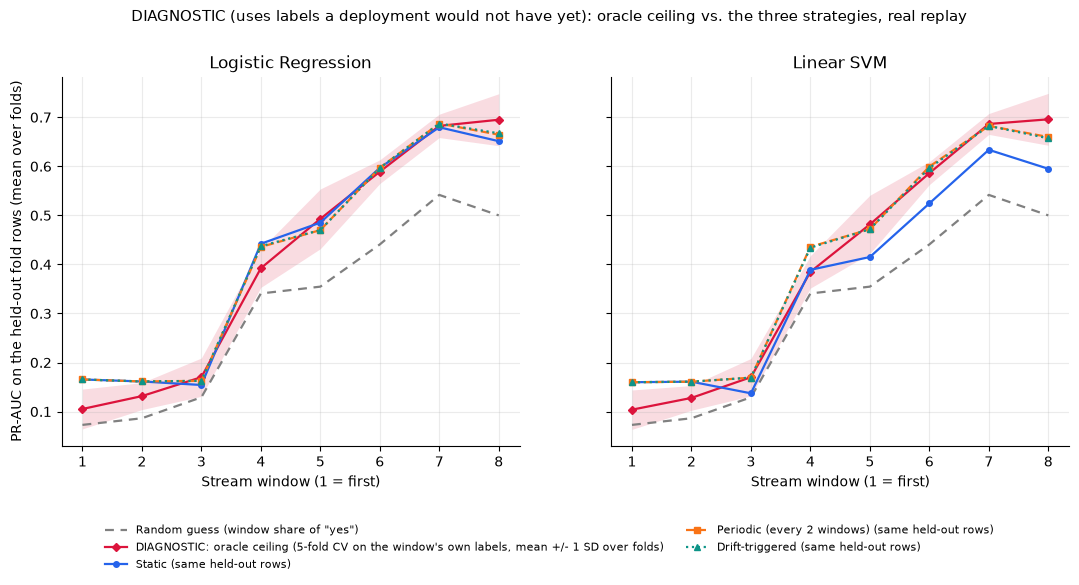

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, m in zip(axes, MODELS):
    c = ceiling[ceiling.model == m].sort_values('window')
    ax.plot(c.window, c.random_line, color='grey', lw=1.6, ls=(0, (4, 3)), label='Random guess (window share of "yes")')
    ax.fill_between(c.window, c.oracle_mean - c.oracle_sd_over_folds, c.oracle_mean + c.oracle_sd_over_folds, color='crimson', alpha=0.15, lw=0)
    ax.plot(c.window, c.oracle_mean, '-D', color='crimson', ms=4, lw=1.6, label='DIAGNOSTIC: oracle ceiling (5-fold CV on the window\'s own labels, mean +/- 1 SD over folds)')
    for s in STRATEGIES:
        ax.plot(c.window, c[s], LS[s], color=COL[s], marker=MK[s], ms=4, lw=1.6, label=LABEL[s] + ' (same held-out rows)')
    ax.set_xlabel('Stream window (1 = first)'); ax.set_xticks(range(1, 9)); ax.set_title(m)
axes[0].set_ylabel('PR-AUC on the held-out fold rows (mean over folds)')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.17), fontsize=8)
fig.suptitle('DIAGNOSTIC (uses labels a deployment would not have yet): oracle ceiling vs. the three strategies, real replay', y=1.02, fontsize=11)
save_fig(fig, '20_oracle_ceiling.png'); plt.show()

# Part C: DIAGNOSTIC 2, paired bootstrap intervals

**Method.** For each scenario, model and seed, and for each of the 8 windows, resample the window's rows with replacement (2,000 resamples; **the same resample is used for all three strategies**), compute each strategy's PR-AUC on the resample, take the mean over the 8 windows, and form the difference: periodic minus static and drift-triggered minus static. The 95% interval is the 2.5th to 97.5th percentile of the 2,000 differences. The bootstrap RNG seed (2026) is declared here and not tuned.

**Fast PR-AUC.** Calling scikit-learn 1.1 million times would take about 40 minutes, so PR-AUC for all 2,000 resamples is computed at once from sorted scores and resample counts (ties between equal scores are handled as scikit-learn does). It is **validated first**: if its largest difference from `average_precision_score` exceeds 0.001, the notebook stops.

**Limitations (also in `RESULTS_SUMMARY.md`).** The intervals reflect *which customers appear in each window*, not training randomness (the models are deterministic). The 3 seeds are **not independent replications**: the real replay is identical across seeds, and the synthetic seeds resample one fixed set of training rows. The intervals say nothing about other time periods or other data.

In [17]:
def ap_matrix(counts, y, scores):
    """PR-AUC (average precision) for many resamples at once. counts: (B, n) how often each row is drawn."""
    order = np.argsort(-scores, kind='stable')
    s, ys, wc = scores[order], y[order], counts[:, order]
    starts = np.r_[0, np.flatnonzero(s[1:] != s[:-1]) + 1]          # equal scores form one threshold step (as in scikit-learn)
    wy = np.add.reduceat(wc * ys, starts, axis=1).astype(float)
    wn = np.add.reduceat(wc, starts, axis=1).astype(float)
    tp, seen = np.cumsum(wy, axis=1), np.cumsum(wn, axis=1)
    precision = np.divide(tp, seen, out=np.zeros_like(tp), where=seen > 0)
    return (wy * precision).sum(axis=1) / wy.sum(axis=1)

B, BOOT_SEED = 2000, 2026
# Validation 1: full data (every row counted once) against average_precision_score, all windows
d_full = max(abs(ap_matrix(np.ones((1, len(e['y'])), dtype=np.int64), e['y'], e['scores'])[0] - average_precision_score(e['y'], e['scores'])) for e in store)
# Validation 2: real bootstrap draws against average_precision_score (sample_weight = counts, and explicit row resampling)
vrng = np.random.default_rng(7); d_boot = 0.0; n_checked = 0
for e in store[::12]:
    n = len(e['y']); counts = vrng.multinomial(n, np.full(n, 1 / n), size=6)
    fast = ap_matrix(counts, e['y'], e['scores'])
    for b in range(6):
        d_boot = max(d_boot, abs(fast[b] - average_precision_score(e['y'], e['scores'], sample_weight=counts[b])))
        rows_b = np.repeat(np.arange(n), counts[b])
        d_boot = max(d_boot, abs(fast[b] - average_precision_score(e['y'][rows_b], e['scores'][rows_b]))); n_checked += 1
print(f'Largest difference from average_precision_score: full windows {d_full:.2e} ({len(store)} windows); bootstrap draws {d_boot:.2e} ({n_checked} draws, both ways)')
assert max(d_full, d_boot) <= 0.001, 'fast PR-AUC differs from scikit-learn by more than 0.001: STOP and explain'
print('Validation passed (limit 0.001).')

Largest difference from average_precision_score: full windows 1.11e-16 (576 windows); bootstrap draws 1.11e-16 (288 draws, both ways)
Validation passed (limit 0.001).


In [18]:
rng = np.random.default_rng(BOOT_SEED); t0 = time.perf_counter(); rows = []
for scenario in SCEN:
    for model_name in MODELS:
        for seed in SEEDS:
            diff = {'periodic': np.zeros(B), 'drift_triggered': np.zeros(B)}; est = {'periodic': 0.0, 'drift_triggered': 0.0}
            for w in range(1, N_STREAM_WINDOWS + 1):
                es = {s: idx_store[(scenario, model_name, seed, s, w)] for s in STRATEGIES}
                y = es['static']['y']; n = len(y)
                assert all(np.array_equal(es[s]['y'], y) and np.array_equal(es[s]['index'], es['static']['index']) for s in STRATEGIES)
                counts = rng.multinomial(n, np.full(n, 1 / n), size=B)         # ONE resample, used by all strategies
                ap = {s: ap_matrix(counts, y, es[s]['scores']) for s in STRATEGIES}
                for s in diff:
                    diff[s] += (ap[s] - ap['static']) / N_STREAM_WINDOWS
                    est[s] += (average_precision_score(y, es[s]['scores']) - average_precision_score(y, es['static']['scores'])) / N_STREAM_WINDOWS
            for s in diff:
                lo, hi = np.percentile(diff[s], [2.5, 97.5])
                rows.append({'scenario': scenario, 'model': model_name, 'seed': seed, 'comparison': f'{s} minus static', 'observed_mean_difference': est[s],
                             'bootstrap_mean': diff[s].mean(), 'ci95_low': lo, 'ci95_high': hi, 'interval_contains_zero': bool(lo <= 0 <= hi)})
boot = pd.DataFrame(rows)
save_table(boot, '07_C_bootstrap_intervals.csv')
print(f'Bootstrap finished in {time.perf_counter() - t0:.0f} s ({B} resamples per window)')
# observed difference must equal the one implied by results_v2.csv
chk = v2.pivot_table(index=['scenario', 'model', 'seed', 'window'], columns='strategy', values='pr_auc')
chk['p'] = chk.periodic - chk.static; chk['d'] = chk.drift_triggered - chk.static
chk = chk.groupby(['scenario', 'model', 'seed'])[['p', 'd']].mean().reset_index()
m = boot.merge(chk, on=['scenario', 'model', 'seed']); m['v2'] = np.where(m.comparison.str.startswith('periodic'), m.p, m.d)
print('Largest gap between the observed differences here and those implied by results_v2.csv:', float((m.observed_mean_difference - m.v2).abs().max()))
boot.round(4)

Bootstrap finished in 47 s (2000 resamples per window)
Largest gap between the observed differences here and those implied by results_v2.csv: 0.0


,scenario,model,seed,comparison,observed_mean_difference,bootstrap_mean,ci95_low,ci95_high,interval_contains_zero
0,real_replay,Logistic Regression,42,periodic minus static,0.0016,0.0018,-0.0065,0.0104,True
1,real_replay,Logistic Regression,42,drift_triggered minus static,0.0013,0.0013,-0.0070,0.0100,True
2,real_replay,Logistic Regression,43,periodic minus static,0.0016,0.0019,-0.0065,0.0104,True
3,real_replay,Logistic Regression,43,drift_triggered minus static,0.0013,0.0015,-0.0068,0.0102,True
4,real_replay,Logistic Regression,44,periodic minus static,0.0016,0.0019,-0.0066,0.0108,True
5,real_replay,Logistic Regression,44,drift_triggered minus static,0.0013,0.0015,-0.0073,0.0100,True
6,real_replay,Linear SVM,42,periodic minus static,0.0393,0.0396,0.0276,0.0521,False
7,real_replay,Linear SVM,42,drift_triggered minus static,0.0376,0.0379,0.0254,0.0506,False
8,real_replay,Linear SVM,43,periodic minus static,0.0393,0.0393,0.0266,0.0520,False
9,real_replay,Linear SVM,43,drift_triggered minus static,0.0376,0.0375,0.0249,0.0503,False


,scenario,model,comparison,mean_difference,ci_low_min,ci_high_max,seeds_with_interval_excluding_zero
0,gradual,Linear SVM,drift_triggered minus static,-0.0002,-0.0066,0.0080,0
1,gradual,Linear SVM,periodic minus static,0.0007,-0.0041,0.0088,0
2,gradual,Logistic Regression,drift_triggered minus static,0.0008,-0.0055,0.0079,0
3,gradual,Logistic Regression,periodic minus static,0.0017,-0.0031,0.0086,0
4,real_replay,Linear SVM,drift_triggered minus static,0.0376,0.0249,0.0506,3
5,real_replay,Linear SVM,periodic minus static,0.0393,0.0266,0.0522,3
6,real_replay,Logistic Regression,drift_triggered minus static,0.0013,-0.0073,0.0102,0
7,real_replay,Logistic Regression,periodic minus static,0.0016,-0.0066,0.0108,0
8,stationary,Linear SVM,drift_triggered minus static,0.0000,0.0000,0.0000,0
9,stationary,Linear SVM,periodic minus static,0.0009,-0.0034,0.0063,0


saved figures/21_bootstrap_intervals.png


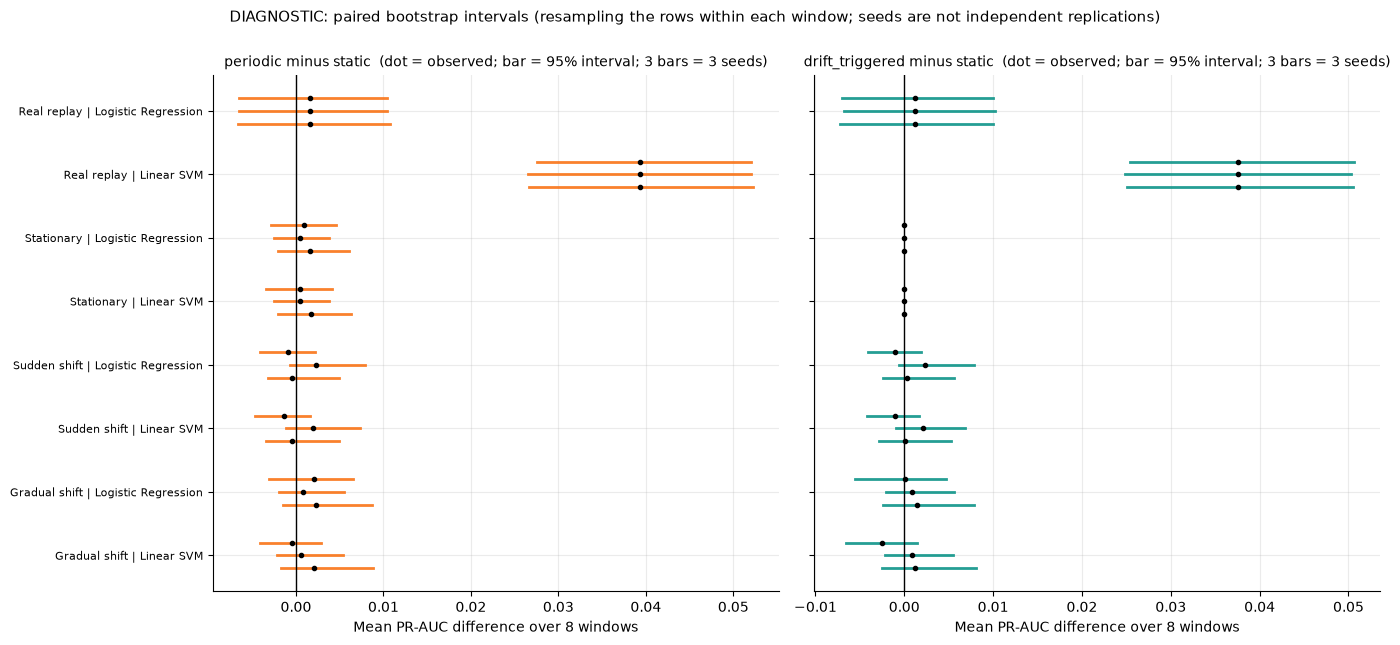

In [19]:
summary_boot = (boot.assign(scenario_model=boot.scenario + ' | ' + boot.model)
                .groupby(['scenario', 'model', 'comparison'])
                .agg(mean_difference=('observed_mean_difference', 'mean'), ci_low_min=('ci95_low', 'min'), ci_high_max=('ci95_high', 'max'),
                     seeds_with_interval_excluding_zero=('interval_contains_zero', lambda x: int((~x).sum()))).reset_index())
save_table(summary_boot, '07_C_bootstrap_summary.csv'); display(summary_boot.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 6.4), sharex=False)
for ax, cmpn in zip(axes, ['periodic minus static', 'drift_triggered minus static']):
    ylabels, y = [], 0
    for scenario in SCEN:
        for model_name in MODELS:
            for k, seed in enumerate(SEEDS):
                r = boot[(boot.scenario == scenario) & (boot.model == model_name) & (boot.seed == seed) & (boot.comparison == cmpn)].iloc[0]
                ax.plot([r.ci95_low, r.ci95_high], [y - 0.2 + 0.2 * k] * 2, color=COL['periodic' if cmpn.startswith('periodic') else 'drift_triggered'], lw=2, alpha=0.9)
                ax.plot(r.observed_mean_difference, y - 0.2 + 0.2 * k, 'o', color='black', ms=3)
            ylabels.append(f'{SCEN_TITLE[scenario].split(" (")[0]} | {model_name}'); y += 1
    ax.axvline(0, color='black', lw=1); ax.set_yticks(range(y)); ax.set_yticklabels(ylabels if ax is axes[0] else [''] * y, fontsize=8); ax.invert_yaxis()
    ax.set_xlabel('Mean PR-AUC difference over 8 windows'); ax.set_title(cmpn + '  (dot = observed; bar = 95% interval; 3 bars = 3 seeds)', fontsize=10)
fig.suptitle('DIAGNOSTIC: paired bootstrap intervals (resampling the rows within each window; seeds are not independent replications)', y=1.0, fontsize=11)
fig.tight_layout(); save_fig(fig, '21_bootstrap_intervals.png'); plt.show()

# Part D: brief error analysis (descriptive only)

Real replay, **static Logistic Regression** at its recorded threshold (one fixed cut-off for all windows, because the static model never refits): which subscribers does it catch (true positives) and which does it miss (false negatives)? All 8 windows are pooled; windows 4 to 8, which hold most of the subscribers, dominate. The groups come from the baseline features. Groups with fewer than 30 subscribers are flagged. This describes the model; it does not explain *why* these customers are missed.

In [20]:
parts = []
for w in range(1, N_STREAM_WINDOWS + 1):
    e = idx_store[('real_replay', 'Logistic Regression', 42, 'static', w)]
    part = df.loc[e['index'], ['age', 'job', 'poutcome', 'previous']].copy()
    part['window'], part['y'], part['predicted'] = w, e['y'], (e['scores'] >= e['threshold']).astype(int)
    parts.append(part)
err = pd.concat(parts)
err['age_group'] = pd.cut(err.age, [0, 29, 39, 49, 59, 200], labels=['<30', '30-39', '40-49', '50-59', '60+'])
err['repeat_customer'] = np.where(err.previous > 0, 'previous contact', 'no previous contact')
subs = err[err.y == 1]
print('Threshold used by the static model (same in every window):', sorted(set(round(idx_store[('real_replay', 'Logistic Regression', 42, 'static', w)]['threshold'], 4) for w in range(1, 9))))
print(f'Subscribers: {len(subs)}; caught {int(subs.predicted.sum())}; missed {int((1 - subs.predicted).sum())}; overall recall {subs.predicted.mean():.3f}; predicted yes in total {int(err.predicted.sum())} of {len(err)} rows')
tables = []
for var in ['age_group', 'job', 'poutcome', 'repeat_customer']:
    t = (subs.groupby(var, observed=True).agg(subscribers=('y', 'size'), caught=('predicted', 'sum')).reset_index().rename(columns={var: 'group'}))
    t.insert(0, 'variable', var); t['missed'] = t.subscribers - t.caught; t['recall'] = t.caught / t.subscribers
    t['share_of_all_subscribers'] = t.subscribers / len(subs); t['small_group_under_30'] = t.subscribers < 30
    pred = err.groupby(var, observed=True).agg(rows=('y', 'size'), predicted_yes=('predicted', 'sum')).reset_index().rename(columns={var: 'group'})
    t = t.merge(pred, on='group'); t['precision'] = t.caught / t.predicted_yes.replace(0, np.nan)
    tables.append(t)
error_table = pd.concat(tables, ignore_index=True)
save_table(error_table, '07_D_caught_vs_missed_by_group.csv')
error_table.round(3)

Threshold used by the static model (same in every window): [0.5228]
Subscribers: 2540; caught 1493; missed 1047; overall recall 0.588; predicted yes in total 3669 of 8238 rows


,variable,group,subscribers,caught,missed,recall,share_of_all_subscribers,small_group_under_30,rows,predicted_yes,precision
0,age_group,<30,588,459,129,0.781,0.231,False,1945,1306,0.351
1,age_group,30-39,837,497,340,0.594,0.330,False,3051,1361,0.365
2,age_group,40-49,367,154,213,0.420,0.144,False,1359,302,0.510
3,age_group,50-59,360,153,207,0.425,0.142,False,1037,287,0.533
4,age_group,60+,388,230,158,0.593,0.153,False,846,413,0.557
5,job,admin.,794,437,357,0.550,0.313,False,2382,955,0.458
6,job,blue-collar,216,98,118,0.454,0.085,False,1295,436,0.225
7,job,entrepreneur,45,29,16,0.644,0.018,False,195,117,0.248
8,job,housemaid,67,26,41,0.388,0.026,False,180,37,0.703
9,job,management,169,106,63,0.627,0.067,False,524,237,0.447


saved figures/22_error_analysis_recall_by_group.png


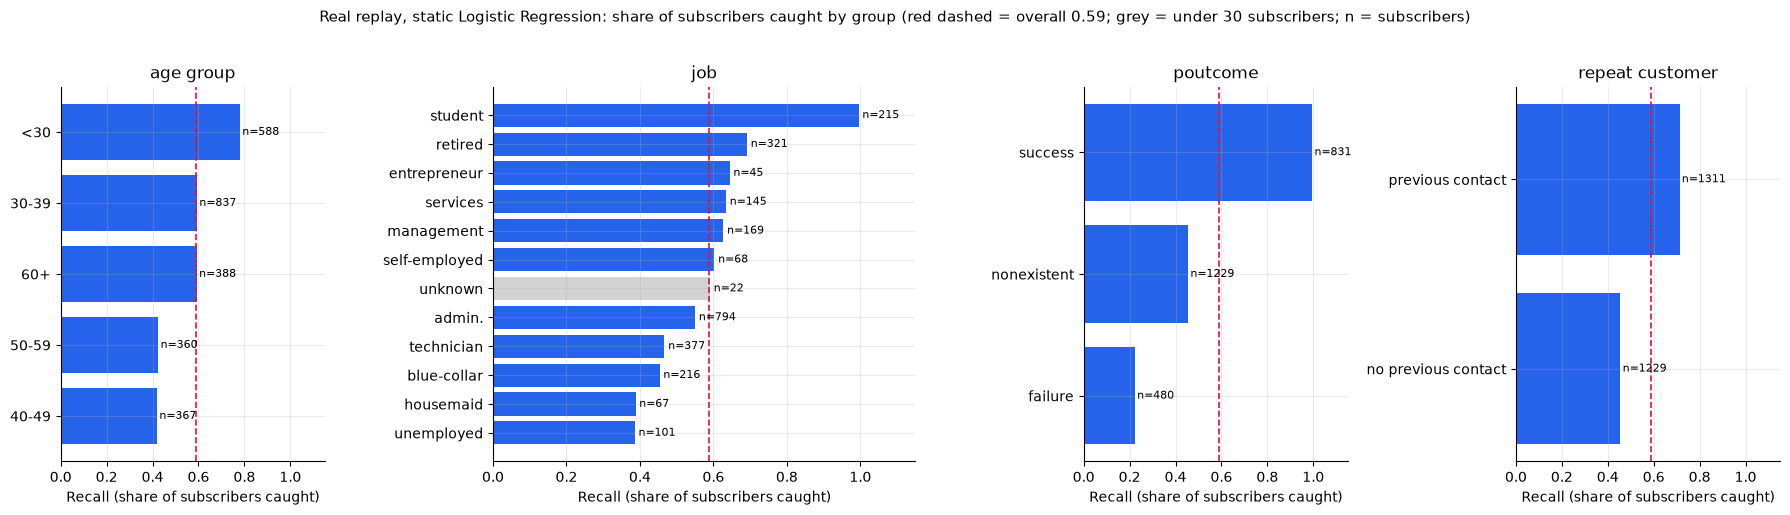

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5), gridspec_kw={'width_ratios': [1, 1.6, 1, 1]})
overall = subs.predicted.mean()
for ax, var in zip(axes, ['age_group', 'job', 'poutcome', 'repeat_customer']):
    t = error_table[error_table.variable == var].sort_values('recall')
    ax.barh(t.group.astype(str), t.recall, color=np.where(t.small_group_under_30, 'lightgrey', COL['static']))
    for yy, (r, n) in enumerate(zip(t.recall, t.subscribers)): ax.text(r + 0.01, yy, f'n={n}', va='center', fontsize=8)
    ax.axvline(overall, color='crimson', ls='--', lw=1.2); ax.set_xlim(0, 1.15); ax.set_xlabel('Recall (share of subscribers caught)'); ax.set_title(var.replace('_', ' '))
fig.suptitle(f'Real replay, static Logistic Regression: share of subscribers caught by group (red dashed = overall {overall:.2f}; grey = under 30 subscribers; n = subscribers)', y=1.02, fontsize=11)
fig.tight_layout(); save_fig(fig, '22_error_analysis_recall_by_group.png'); plt.show()

# Final checks

In [22]:
assert sha(V1) == HASH_AT_START[V1.name] and sha(V2) == HASH_AT_START[V2.name]
print('results.csv and results_v2.csv unchanged:'); [print(' ', k, v) for k, v in HASH_AT_START.items()]
print('Tables written:', sorted(p.name for p in TAB.glob('07_*.csv')))

results.csv and results_v2.csv unchanged:
  results.csv 2b979e130f12d5c617c1664edbf6c67a9e0ad83455a39ef86d5f4f4eba5f8109
  results_v2.csv 33159ac1305a2301a15fda5c2397b3e129297a6e309b69d0b494c8413298a6f4
Tables written: ['07_A3_comparison_table.csv', '07_A4_detection_delay_false_alarms.csv', '07_A4_retraining_effect_vs_static.csv', '07_A4_static_before_vs_after_change.csv', '07_A5_yes_share_vs_pr_auc.csv', '07_A6_v1_vs_v2_synthetic.csv', '07_A7_training_set_composition.csv', '07_B_oracle_ceiling.csv', '07_B_oracle_ceiling_summary.csv', '07_C_bootstrap_intervals.csv', '07_C_bootstrap_summary.csv', '07_D_caught_vs_missed_by_group.csv']
